# 04 — Contrastive Fusion (Dual Encoder)

**Project 2.2 — Cross-Modal Retrieval: Mobile App Screens and Text Summaries**
Tess Santhosh (a2910201) · COMP 1030 Multimodal Data Analytics, Adelaide University

Trains a **contrastive dual encoder** (CLIP-style): separate projection heads map image and text
features into a shared embedding space using `info_nce` loss, so matching pairs end up close and
non-matching pairs end up far apart. This is expected to be the strongest technique, since InfoNCE
trains directly for cross-modal alignment unlike notebook 03's early fusion and it's also the
most efficient, since each modality is encoded once and cached, so a query needs only one encode +
one dot product, not a re-run per candidate.

**Outputs saved:**
- `results/figures/fig7_contrastive_loss_curve.png`, `fig8_contrastive_score_heatmap.png`
- `results/tables/contrastive_fusion_metrics.csv`, `contrastive_fusion_parameter_counts.csv`,
  `contrastive_temperature_sweep.csv`

## Setup

In [ ]:
#repo setup
import os, sys, subprocess

REPO_URL = "https://github.com/tesssanthosh/cross-modal-retrieval-2.2.git"
REPO_DIR = "/content/cross-modal-retrieval-2.2"

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())


Working directory: /content/cross-modal-retrieval-2.2


In [ ]:
!pip install -q -r requirements.txt
!pip install -q datasets


In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from src.utils import (
    count_parameters, retrieval_report, cosine_score_matrix, recall_at_k,
    load_rico_splits_with_features, build_screen_idx, PairDataset, info_nce,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/tables", exist_ok=True)


Device: cuda
GPU: Tesla T4


## Load data and features

In [ ]:
data, resnet, bert = load_rico_splits_with_features(DEVICE)
screen_idx = build_screen_idx(data)
#this notebook only uses the cached features
for split_name, d in data.items():
    print(f"{split_name}: {d['image_features'].shape[0]} screens, "
          f"{len(d['flat_df'])} captions, eval set {len(d['eval_df'])} screens")


del resnet, bert
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (35 outputs left out)

BERT features:   0%|          | 0/93 [00:00<?, ?it/s]

ResNet-50 features:   0%|          | 0/68 [00:00<?, ?it/s]

BERT features:   0%|          | 0/169 [00:00<?, ?it/s]

train: 15743 screens, 78715 captions, eval set 15743 screens
val: 2364 screens, 11820 captions, eval set 2364 screens
test: 4310 screens, 21550 captions, eval set 4310 screens


## Architecture: two projection heads into a shared space

`EMBED_DIM = 256` is smaller than either frozen feature space (2048-d image, 768-d text), forcing
the model to compress down to what actually matters for matching. Both heads are small MLPs and kept
comparable in parameter count to notebook 03's scorer for a fair comparison in notebook 05.

In [ ]:
EMBED_DIM = 256


class ImageProjector(nn.Module):
    def __init__(self, in_dim=2048, hidden=512, out_dim=EMBED_DIM, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


class TextProjector(nn.Module):
    def __init__(self, in_dim=768, hidden=512, out_dim=EMBED_DIM, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


BATCH_SIZE = 512  # bigger than notebook 03 as it helps contrastive training

train_loader = DataLoader(
    PairDataset(data["train"]["flat_df"], data["train"]["image_features"],
                data["train"]["flat_text_features"], screen_idx["train"]),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(
    PairDataset(data["val"]["flat_df"], data["val"]["image_features"],
                data["val"]["flat_text_features"], screen_idx["val"]),
    batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

probe_image_proj = ImageProjector().to(DEVICE)
probe_text_proj = TextProjector().to(DEVICE)
print(f"ImageProjector: {count_parameters(probe_image_proj):,} parameters")
print(f"TextProjector:  {count_parameters(probe_text_proj):,} parameters")
print(f"Combined trainable parameters: "
      f"{count_parameters(probe_image_proj) + count_parameters(probe_text_proj):,}")
del probe_image_proj, probe_text_proj


ImageProjector: 1,180,416 parameters
TextProjector:  525,056 parameters
Combined trainable parameters: 1,705,472


## Training function

Trains both heads jointly with `info_nce` from `src/utils.py`. Early stopping watches
validation InfoNCE loss only and retrieval metrics are computed separately, after
training and not used to decide when to stop.

In [ ]:
MAX_EPOCHS = 30
PATIENCE = 4
LR = 1e-3


def train_dual_encoder(temperature, seed=SEED, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    image_proj = ImageProjector().to(DEVICE)
    text_proj = TextProjector().to(DEVICE)
    opt = torch.optim.Adam(list(image_proj.parameters()) + list(text_proj.parameters()), lr=LR)

    history = {"train_loss": [], "val_loss": []}
    best_val, best_epoch, bad_epochs = float("inf"), 0, 0
    best_state = None

    for epoch in range(1, MAX_EPOCHS + 1):
        image_proj.train(); text_proj.train()
        train_losses = []
        for imgs, txts in train_loader:
            imgs, txts = imgs.to(DEVICE), txts.to(DEVICE)
            opt.zero_grad()
            img_emb = nn.functional.normalize(image_proj(imgs), dim=1)
            txt_emb = nn.functional.normalize(text_proj(txts), dim=1)
            loss = info_nce(img_emb, txt_emb, temperature=temperature)
            loss.backward()
            opt.step()
            train_losses.append(loss.item())

        image_proj.eval(); text_proj.eval()
        val_losses = []
        with torch.no_grad():
            for imgs, txts in val_loader:
                imgs, txts = imgs.to(DEVICE), txts.to(DEVICE)
                img_emb = nn.functional.normalize(image_proj(imgs), dim=1)
                txt_emb = nn.functional.normalize(text_proj(txts), dim=1)
                val_losses.append(info_nce(img_emb, txt_emb, temperature=temperature).item())

        train_loss = sum(train_losses) / len(train_losses)
        val_loss = sum(val_losses) / len(val_losses)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            print(f"  epoch {epoch:2d}: train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

        if val_loss < best_val - 1e-4:
            best_val, best_epoch, bad_epochs = val_loss, epoch, 0
            best_state = {
                "image_proj": {k: v.detach().cpu().clone() for k, v in image_proj.state_dict().items()},
                "text_proj": {k: v.detach().cpu().clone() for k, v in text_proj.state_dict().items()},
            }
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                if verbose:
                    print(f"  Early stopping at epoch {epoch} "
                          f"(best val_loss={best_val:.4f} at epoch {best_epoch}).")
                break

    image_proj.load_state_dict(best_state["image_proj"])
    text_proj.load_state_dict(best_state["text_proj"])
    return image_proj, text_proj, history, best_val


## Temperature sweep (selected by validation Recall@10)

A dual encoders full retrieval score matrix is cheap to compute unlike notebook 03's early-fusion scorer, so there's no need for a cheaper proxy metric
here. Each temperature setting is fully trained with its own early stopping on validation loss,
then evaluated directly by validation Recall@10.

In [ ]:
@torch.no_grad()
def encode_and_eval(image_proj, text_proj, split_name, temperature=None):
    # encodes the eval set and returns (retrieval_report, score matrix)
    image_proj.eval(); text_proj.eval()
    d = data[split_name]
    img_emb = nn.functional.normalize(image_proj(d["image_features"].to(DEVICE)), dim=1)
    txt_emb = nn.functional.normalize(text_proj(d["eval_text_features"].to(DEVICE)), dim=1)
    scores = cosine_score_matrix(img_emb, txt_emb).cpu()
    return retrieval_report(scores, ks=(1, 5, 10)), scores


TEMPERATURES = [0.05, 0.07, 0.1]
sweep_rows = []
sweep_results = {}

for temp in TEMPERATURES:
    print(f"--- temperature {temp} ---")
    img_proj_t, txt_proj_t, hist_t, best_val_loss_t = train_dual_encoder(temp, verbose=True)
    val_report_t, _ = encode_and_eval(img_proj_t, txt_proj_t, "val")
    sweep_rows.append({
        "temperature": temp, "best_val_loss": best_val_loss_t,
        "val_R@10_image->text": val_report_t["R@10 image->text"],
        "val_R@10_text->image": val_report_t["R@10 text->image"],
    })
    sweep_results[temp] = (img_proj_t, txt_proj_t, hist_t)

sweep_df = pd.DataFrame(sweep_rows)
sweep_df["val_R@10_mean"] = sweep_df[["val_R@10_image->text", "val_R@10_text->image"]].mean(axis=1)
sweep_df.to_csv("results/tables/contrastive_temperature_sweep.csv", index=False)
print()
print(sweep_df.to_string(index=False))

BEST_TEMPERATURE = sweep_df.loc[sweep_df["val_R@10_mean"].idxmax(), "temperature"]
print(f"\nSelected temperature (by validation Recall@10): {BEST_TEMPERATURE}")

image_proj, text_proj, history = (sweep_results[BEST_TEMPERATURE][0],
                                   sweep_results[BEST_TEMPERATURE][1],
                                   sweep_results[BEST_TEMPERATURE][2])


--- temperature 0.05 ---
  epoch  1: train_loss=5.6257  val_loss=5.4188
  epoch  2: train_loss=4.8579  val_loss=5.3486
  epoch  3: train_loss=4.4280  val_loss=5.4334
  epoch  4: train_loss=4.1009  val_loss=5.5804
  epoch  5: train_loss=3.8304  val_loss=5.6778
  epoch  6: train_loss=3.6065  val_loss=5.7821
  Early stopping at epoch 6 (best val_loss=5.3486 at epoch 2).
--- temperature 0.07 ---
  epoch  1: train_loss=5.5321  val_loss=5.4047
  epoch  2: train_loss=4.7932  val_loss=5.3650
  epoch  3: train_loss=4.3666  val_loss=5.4581
  epoch  4: train_loss=4.0477  val_loss=5.5407
  epoch  5: train_loss=3.7947  val_loss=5.6135
  epoch  6: train_loss=3.5860  val_loss=5.7376
  Early stopping at epoch 6 (best val_loss=5.3650 at epoch 2).
--- temperature 0.1 ---
  epoch  1: train_loss=5.4301  val_loss=5.3612
  epoch  2: train_loss=4.7314  val_loss=5.3539
  epoch  3: train_loss=4.3290  val_loss=5.4175
  epoch  4: train_loss=4.0393  val_loss=5.4640
  epoch  5: train_loss=3.8126  val_loss=5.5155
 

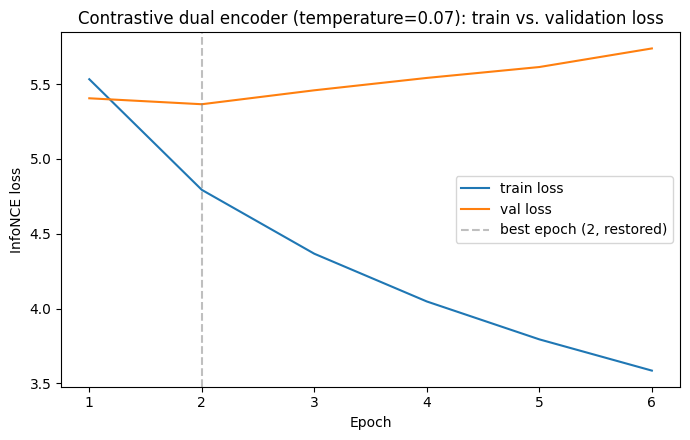

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
epochs = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1
ax.plot(epochs, history["train_loss"], label="train loss")
ax.plot(epochs, history["val_loss"], label="val loss")
ax.axvline(best_epoch, color="gray", linestyle="--", alpha=0.5,
           label=f"best epoch ({best_epoch}, restored)")
ax.set_xlabel("Epoch"); ax.set_ylabel("InfoNCE loss")
ax.set_title(f"Contrastive dual encoder (temperature={BEST_TEMPERATURE}): train vs. validation loss")
ax.legend()
fig.tight_layout()
fig.savefig("results/figures/fig7_contrastive_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()


## Full retrieval evaluation (train, val, test)

Scoring is far cheaper here than in notebook 03, so `val` and `test` use their full eval sets, no subsampling. `train` is capped
at 5000 screens, larger than before, but not the full 15,743, since the
AUC calculation on that many pairs crashed a free-tier Colab session on RAM once when I tried. Test is scored once,
only after temperature was fixed using validation.

In [ ]:
MAX_TRAIN_EVAL_SCREENS = 5000


def subsample_idx(n_total, max_n, seed=0):
    if max_n is None or n_total <= max_n:
        return torch.arange(n_total)
    g = torch.Generator().manual_seed(seed)
    return torch.randperm(n_total, generator=g)[:max_n]


@torch.no_grad()
def encode_and_eval_capped(image_proj, text_proj, split_name, max_screens=None):
    image_proj.eval(); text_proj.eval()
    d = data[split_name]
    sel = subsample_idx(d["image_features"].shape[0], max_screens)
    img_feats = d["image_features"][sel].to(DEVICE)
    txt_feats = d["eval_text_features"][sel].to(DEVICE)
    img_emb = nn.functional.normalize(image_proj(img_feats), dim=1)
    txt_emb = nn.functional.normalize(text_proj(txt_feats), dim=1)
    scores = cosine_score_matrix(img_emb, txt_emb).cpu()
    return retrieval_report(scores, ks=(1, 5, 10)), scores


results_by_split = {}
scores_by_split = {}
timings = {}
eval_caps = {"train": MAX_TRAIN_EVAL_SCREENS, "val": None, "test": None}

for split_name in ("train", "val", "test"):
    t0 = time.time()
    report, scores = encode_and_eval_capped(image_proj, text_proj, split_name,
                                             max_screens=eval_caps[split_name])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0
    n = scores.shape[0]
    report["n_screens_scored"] = n
    report["n_pairs_scored"] = n * n
    report["encode_plus_scoring_time_sec"] = round(elapsed, 3)
    report["us_per_pair"] = round(1e6 * elapsed / (n * n), 4)
    results_by_split[split_name] = report
    scores_by_split[split_name] = scores
    timings[split_name] = elapsed
    print(f"{split_name} ({n} screens):"); print(report); print()


train (5000 screens):
{'R@1 image->text': 0.023000000044703484, 'R@1 text->image': 0.022199999541044235, 'R@5 image->text': 0.0843999981880188, 'R@5 text->image': 0.07779999822378159, 'R@10 image->text': 0.13300000131130219, 'R@10 text->image': 0.1257999986410141, 'AUC': np.float64(0.9139347314182837), 'n_screens_scored': 5000, 'n_pairs_scored': 25000000, 'encode_plus_scoring_time_sec': 12.975, 'us_per_pair': 0.519}

val (2364 screens):
{'R@1 image->text': 0.020304568111896515, 'R@1 text->image': 0.019458545371890068, 'R@5 image->text': 0.06472080945968628, 'R@5 text->image': 0.055837564170360565, 'R@10 image->text': 0.10067681968212128, 'R@10 text->image': 0.0956006795167923, 'AUC': np.float64(0.8287476314789187), 'n_screens_scored': 2364, 'n_pairs_scored': 5588496, 'encode_plus_scoring_time_sec': 2.098, 'us_per_pair': 0.3754}

test (4310 screens):
{'R@1 image->text': 0.007424593903124332, 'R@1 text->image': 0.009744779206812382, 'R@5 image->text': 0.031786542385816574, 'R@5 text->ima

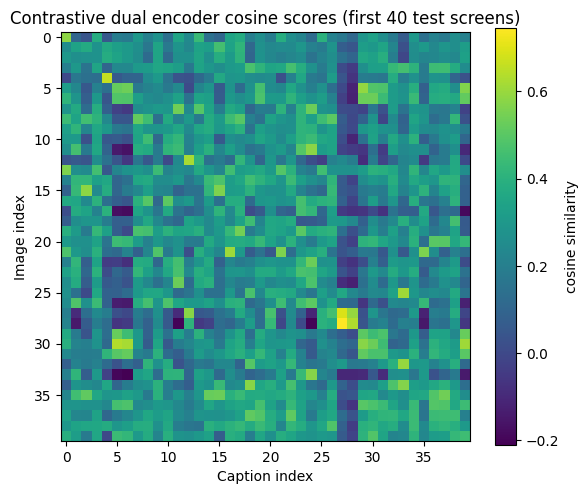

In [ ]:
# score heatmap reusing the test scores already computed above
test_scores = scores_by_split["test"]
N_SHOW = 40
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(test_scores[:N_SHOW, :N_SHOW], cmap="viridis")
ax.set_title(f"Contrastive dual encoder cosine scores (first {N_SHOW} test screens)")
ax.set_xlabel("Caption index"); ax.set_ylabel("Image index")
fig.colorbar(im, ax=ax, label="cosine similarity")
fig.tight_layout()
fig.savefig("results/figures/fig8_contrastive_score_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Per-query cost after the candidate index is built

Once candidates are encoded and cached, answering a new query is
just one encode plus one matrix-vector multiply against the cached index and not a re-run of the
network per candidate, unlike notebook 03. Timed below, repeated several times for stability.

In [ ]:
@torch.no_grad()
def single_query_cost(image_proj, cached_text_emb, n_repeats=50):
    # average time for one image->text query against the cached candidate index
    image_proj.eval()
    query_img = data["test"]["image_features"][:1].to(DEVICE)

    # untimed first call so CUDA's one-off start-up cost isn't counted in the average
    _ = cosine_score_matrix(
        nn.functional.normalize(image_proj(query_img), dim=1).cpu(), cached_text_emb)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    t0 = time.time()
    for _ in range(n_repeats):
        q_emb = nn.functional.normalize(image_proj(query_img), dim=1).cpu()
        _ = cosine_score_matrix(q_emb, cached_text_emb)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / n_repeats


with torch.no_grad():
    cached_test_text_emb = nn.functional.normalize(
        text_proj(data["test"]["eval_text_features"].to(DEVICE)), dim=1).cpu()

ms_per_query_precomputed = 1000 * single_query_cost(image_proj, cached_test_text_emb)
print(f"Per-query cost against a precomputed {len(cached_test_text_emb)}-candidate index: "
      f"{ms_per_query_precomputed:.4f} ms")
print("Compare against notebook 03's early-fusion scorer, which must re-run its network once per "
      "candidate for every new query — see results/tables/early_fusion_metrics.csv's ms_per_pair, "
      "multiplied by the candidate count, for that technique's equivalent per-query cost.")


Per-query cost against a precomputed 4310-candidate index: 1.3227 ms
Compare against notebook 03's early-fusion scorer, which must re-run its network once per candidate for every new query — see results/tables/early_fusion_metrics.csv's ms_per_pair, multiplied by the candidate count, for that technique's equivalent per-query cost.


## Save results

In [ ]:
rows = []
for split_name, report in results_by_split.items():
    row = {"technique": "Contrastive dual encoder", "split": split_name}
    row.update(report)
    rows.append(row)

contrastive_results_df = pd.DataFrame(rows)
contrastive_results_df.to_csv("results/tables/contrastive_fusion_metrics.csv", index=False)
contrastive_results_df


,technique,split,R@1 image->text,R@1 text->image,R@5 image->text,R@5 text->image,R@10 image->text,R@10 text->image,AUC,n_screens_scored,n_pairs_scored,encode_plus_scoring_time_sec,us_per_pair
0,Contrastive dual encoder,train,0.023000,0.022200,0.084400,0.077800,0.133000,0.125800,0.913935,5000,25000000,12.975,0.5190
1,Contrastive dual encoder,val,0.020305,0.019459,0.064721,0.055838,0.100677,0.095601,0.828748,2364,5588496,2.098,0.3754
2,Contrastive dual encoder,test,0.007425,0.009745,0.031787,0.037819,0.054988,0.057541,0.827628,4310,18576100,8.545,0.4600


In [ ]:
param_rows = [{
    "model": "Contrastive dual encoder (image + text projection heads)",
    "trainable_parameters": count_parameters(image_proj) + count_parameters(text_proj),
    "embedding_dim": EMBED_DIM,
    "selected_temperature": BEST_TEMPERATURE,
    "ms_per_query_precomputed_index": round(ms_per_query_precomputed, 4),
}]
pd.DataFrame(param_rows).to_csv("results/tables/contrastive_fusion_parameter_counts.csv", index=False)
pd.DataFrame(param_rows)


,model,trainable_parameters,embedding_dim,selected_temperature,ms_per_query_precomputed_index
0,Contrastive dual encoder (image + text project...,1705472,256,0.07,1.3227
